Author: Enikő Gergely <br>
Date: October 2026
    
# Automated Data Collection for Hitter Posture Analysis

This notebook includes automated data collection for hitter posture analysis. Videos are downloaded from Baseball Savant for the given time period/year and hitter (home games only). Then frames are cut from the video and hitter is cropped from the image.
Cropped images are saved to a folder including player name and year.

The goal is to automate the data collection process for my previous  [study](https://github.com/enikogergely26/YelichPostureAnalysis/blob/main/Christian%20Yelich%20Posture%20Analysis%20-%20EnikoGergely.pdf) and see if the automated process gives the same results that I got with the manual data collection. If results are the same, the automated process can be used to analyze other players and analyze further the relationship between the Back-Gluteal angle and the batting performance. 

# Packages

In [1]:
# import functions from baseballcv - download videos:
from baseballcv.functions.savant_scraper import BaseballSavVideoScraper


# import functions from baseballcv - frames
from baseballcv.datasets.processing.datasets_processor import DatasetProcessor

# import functions from baseballcv - crop hitter from frames
from baseballcv.functions.load_tools import LoadTools
from ultralytics import YOLO
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Inputs

year (int): Year of the qeury. <br>
player (int): A player ID (i.e. 12345). <br>
player_name (str): Player name used for output folder names. <br>
team_abbr (str): Player's team abbreviation (i.e. MIL). <br>


In [2]:
#Inputs:

#----------------
# PLAYER INPUTS:
#----------------
year = 2024
player= 592885
player_name = 'Yelich'
team_abbr= 'MIL'



#-----------------
# DO NOT CHANGE:
#-----------------

# VIDEO INPUTS
max_return_videos= 200
max_videos_per_game= 3

start_dt= str(year) +'-04-01' # 04-01 are used for yearly data
end_dt = str(year) +'-09-15'   # 09-15 are used for yearly data
pitch_type= 'FF'

# videos folder:
videos_download_folder= Path(f"{player_name}({player})") / f"savant_videos_{player_name}_{year}"

# frames and cropped images:
output_frames_folder = Path(f"{player_name}({player})") / f"hitting_frames_{player_name}_{year}"
cropped_images_output_folder = Path(f"{player_name}({player})") /f"cropped_images_{player_name}_{year}"

# Step 1: Download Videos from BaseballSavant

I use BaseballCV Python package to download videos from BaseballSavant.

In [3]:
scraper = BaseballSavVideoScraper.from_date_range(start_dt= start_dt, 
                                                  end_dt = end_dt,  
                                                  team_abbr= team_abbr,
                                                  player= player,  
                                                  pitch_type= pitch_type, 
                                                  download_folder= videos_download_folder, 
                                                  max_return_videos= max_return_videos,  
                                                  max_videos_per_game= max_videos_per_game)

#load pitch level information into a dataframe
df = scraper.play_ids_df


2026-10-23 11:25:25,054 - gameday.py - WARNING - 
            Woah, that's a hefty request you've got there. Please consider using arguments such as 
            `team_abbr` or `player` if you are only looking for a specific team or player to make
            queries faster. 


BaseballCV ⚾ | Extracting Game IDs: 100%|█████████████████████████| 168/168 [01:27<00:00]  1.91it/s, Total time=87.79s
BaseballCV ⚾ | Extracting Game Data: 100%|███████████████████████| 146/146 [05:14<00:00]  2.15s/it, Total time=314.43s


In [4]:
# Filter for home games only:
df = df[df['home_team'] == team_abbr]

# Pitch level information:
print("Number of pitches availbale:", len(df))

# Save final df to excel:
df.to_excel( Path(f"{player_name}({player})")/f"savant_videos_{player_name}_{year}.xlsx" , index=False)

Number of pitches availbale: 90


In [5]:
df.head()

,balls,strikes,outs,play_id,pitch_number_ab,pitch_type,pitch_name,release_speed,sz_top,sz_bot,...,hit_coord_x,hit_coord_y,batter,pitcher,p_throws,inning,inning_top_bot,game_pk,home_team,away_team
0,3,2,0,371e3c5a-59be-4e20-99a1-1448a14d417f,6,FF,Four-Seam Fastball,95.6,3.210000,1.620000,...,113.9,28.41,592885,686973,R,3,bottom,746009,MIL,MIN
1,2,2,0,18f30a6c-85d0-4753-a93e-0723c43fa889,4,FF,Four-Seam Fastball,96.6,3.307064,1.771225,...,NaN,NaN,592885,686973,R,3,bottom,746009,MIL,MIN
2,1,2,1,bf72c54d-770b-42dc-ad49-fd1357ad8db9,3,FF,Four-Seam Fastball,96.5,3.210000,1.620000,...,NaN,NaN,592885,686973,R,1,bottom,746009,MIL,MIN
3,1,0,2,baa336bb-4b94-4bb0-95f3-9a8e0a9492e8,1,FF,Four-Seam Fastball,97.2,3.240000,1.660000,...,NaN,NaN,592885,669302,R,1,bottom,746007,MIL,SEA
4,2,2,2,f32ac78f-52ba-4a76-b00e-450b5872067a,4,FF,Four-Seam Fastball,94.8,3.285707,1.649827,...,NaN,NaN,592885,669302,R,1,bottom,746007,MIL,SEA


In [6]:
# run scraper to download videos (with the name of game_pk + game_id):
scraper.play_ids_df = df
scraper.run_executor()

BaseballCV ⚾ | Downloading Videos:   0%|                                                        | 0/90 [00:00<?] ?it/s

2026-10-23 11:32:17,277 - BaseballSavVideoScraper - INFO - Successfully downloaded video fe1decf9-aee6-4555-adc1-5bd22234401c
2026-10-23 11:32:18,164 - BaseballSavVideoScraper - INFO - Successfully downloaded video f32ac78f-52ba-4a76-b00e-450b5872067a
2026-10-23 11:32:19,677 - BaseballSavVideoScraper - INFO - Successfully downloaded video c3d1ba39-0cc4-4056-8ace-796c8f0845fc
2026-10-23 11:32:20,032 - BaseballSavVideoScraper - INFO - Successfully downloaded video 2f979359-28bd-40f2-9906-39c45aefee99
2026-10-23 11:32:20,398 - BaseballSavVideoScraper - INFO - Successfully downloaded video 18f30a6c-85d0-4753-a93e-0723c43fa889
2026-10-23 11:32:21,136 - BaseballSavVideoScraper - INFO - Successfully downloaded video 1b0913d2-8dc2-46db-9cf8-3bf3b407b0b3
2026-10-23 11:32:21,704 - BaseballSavVideoScraper - INFO - Successfully downloaded video baa336bb-4b94-4bb0-95f3-9a8e0a9492e8
2026-10-23 11:32:21,896 - BaseballSavVideoScraper - INFO - Successfully downloaded video 4f115ef6-a6db-4707-93e7-10dc9

BaseballCV ⚾ | Downloading Videos:   1%|▌                                               | 1/90 [00:26<39:11] 26.42s/it

2026-10-23 11:32:34,969 - BaseballSavVideoScraper - INFO - Successfully downloaded video 19935629-83f0-46b5-9169-0f59b9087884
2026-10-23 11:32:35,347 - BaseballSavVideoScraper - INFO - Successfully downloaded video 76d0f737-5df2-4aa7-b324-060cf23ffb87
2026-10-23 11:32:35,960 - BaseballSavVideoScraper - INFO - Successfully downloaded video ae57daea-679f-4387-81e1-02f73743c870
2026-10-23 11:32:36,201 - BaseballSavVideoScraper - INFO - Successfully downloaded video 19bb7c48-8b8b-469d-864c-cdc5e375ff5f


BaseballCV ⚾ | Downloading Videos:  29%|█████████████▌                                 | 26/90 [00:27<00:49]  1.30it/s

2026-10-23 11:32:36,625 - BaseballSavVideoScraper - INFO - Successfully downloaded video cd68e113-195f-43ef-9793-28db54d39dc7
2026-10-23 11:32:37,313 - BaseballSavVideoScraper - INFO - Successfully downloaded video ae7ac817-f150-4cde-8fc0-f8aa04c0f41e


... (11 outputs left out)

2026-10-23 11:33:12,406 - BaseballSavVideoScraper - INFO - Successfully downloaded video 4966e868-aaf8-406b-96d2-f675e8766bb3
2026-10-23 11:33:13,019 - BaseballSavVideoScraper - INFO - Successfully downloaded video ce1c2516-542a-41ae-b1da-06b93497ee0a
2026-10-23 11:33:13,055 - BaseballSavVideoScraper - INFO - Successfully downloaded video 710290c7-dba3-4807-a287-c0914b282101
2026-10-23 11:33:13,920 - BaseballSavVideoScraper - INFO - Successfully downloaded video f701bf4d-27c3-48cf-8dab-430bb199292b
2026-10-23 11:33:15,674 - BaseballSavVideoScraper - INFO - Successfully downloaded video abea6f4a-542a-4b3e-8bd0-5a675a78bb7b
2026-10-23 11:33:15,675 - BaseballSavVideoScraper - INFO - Successfully downloaded video 04f7ad01-1e16-4db2-85a0-4e60edd77f8d


BaseballCV ⚾ | Downloading Videos:  87%|████████████████████████████████████████▋      | 78/90 [01:07<00:08]  1.37it/s

2026-10-23 11:33:15,697 - BaseballSavVideoScraper - INFO - Successfully downloaded video 0796211f-51c1-4ed5-aab4-e5aef0a25bd0
2026-10-23 11:33:16,325 - BaseballSavVideoScraper - INFO - Successfully downloaded video c81afb17-b01e-44cf-9d30-c1f520888076
2026-10-23 11:33:17,023 - BaseballSavVideoScraper - INFO - Successfully downloaded video 9c754b8f-b521-42fb-9268-8c781088f5fe
2026-10-23 11:33:17,234 - BaseballSavVideoScraper - INFO - Successfully downloaded video 12092f34-6dd8-41a2-ba96-2dffc1dec0fc
2026-10-23 11:33:17,368 - BaseballSavVideoScraper - INFO - Successfully downloaded video b248393f-e8cc-48f7-8235-d08e53962c7d
2026-10-23 11:33:17,982 - BaseballSavVideoScraper - INFO - Successfully downloaded video 5c2c5eae-554f-43d0-9736-c7c5f2a1ec9e


BaseballCV ⚾ | Downloading Videos: 100%|███████████████████████████████████████████████| 90/90 [01:09<00:00]  1.30it/s


# Cut out frames from Videos:
Here I use BaseallCV to cut out the first frame from the downloaded videos. 

This process could be later modified to find the time where the ball reaches home plate and calculate the time of the frame to cut out based on that. With this method I would get a more consistent frame of the hitting stance regarding timing.

In [7]:
""" Args (from BaseballCV documentation)
       video_folder (str): The input folder containing the videos.
       output_frames_folder (str, optional): The output folder name for saving the frames. Defaults to "cv_dataset".
       max_num_frames (int, optional): The number of frames to extract. Defaults to 6000.
       frame_stride (int, optional): The stride resembling n frames in between. Defaults to 30.
"""

processor = DatasetProcessor()
processor.generate_photo_dataset( video_folder = videos_download_folder, 
                                  output_frames_folder =  output_frames_folder,
                                  max_num_frames = 1,
                                  frame_stride = 100)

# Crop Hitter from frames:
Here I use the BaseballCV Python package to crop the hitter from the cutted frames and save to a given folder.

In [8]:
# Initialize LoadTools class
load_tools = LoadTools()

model_weights = load_tools.load_model('phc_detector', model_type = 'YOLO')

model = YOLO(model_weights)


BaseballCV ⚾ | Downloading pitcher_hitter_catcher_detector_v4.pt: 100%|█| 87648115/87648115 [00:24<00:00] 3642408.41iB

2026-10-23 11:33:58,653 - LoadTools - INFO - Model downloaded to models/od/YOLO/pitcher_hitter_catcher_detector/model_weights/pitcher_hitter_catcher_detector_v4.pt


Source Image Updated to 745962_04f7ad01-1e16-4db2-85a0-4e60edd77f8d-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745962_04f7ad01-1e16-4db2-85a0-4e60edd77f8d-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1338.7ms
Speed: 23.8ms preprocess, 1338.7ms inference, 48.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     640.36      246.51      111.69       150.8]]
Class Value: [          2] 

[[     545.67      216.87      117.13      251.69]]
Class Value: [          0] 

[[     621.35      395.99       117.6      306.49]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745962_04f7ad01-1e16-4db2-85a0-4e60edd77f8d-00000.jpg


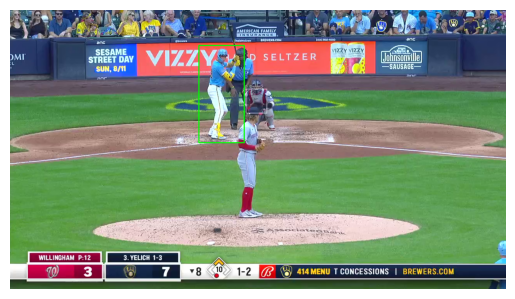

Source Image Updated to 745962_0796211f-51c1-4ed5-aab4-e5aef0a25bd0-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745962_0796211f-51c1-4ed5-aab4-e5aef0a25bd0-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1203.1ms
Speed: 9.8ms preprocess, 1203.1ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     640.36      239.94      106.35      155.97]]
Class Value: [          2] 

[[     546.19      212.92      112.33      252.35]]
Class Value: [          0] 

[[     624.72      391.43      118.96      311.04]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745962_0796211f-51c1-4ed5-aab4-e5aef0a25bd0-00000.jpg


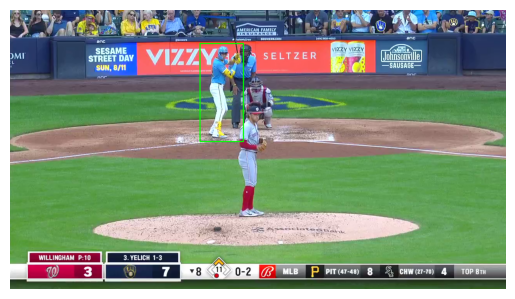

Source Image Updated to 745962_c81afb17-b01e-44cf-9d30-c1f520888076-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745962_c81afb17-b01e-44cf-9d30-c1f520888076-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1174.7ms
Speed: 8.9ms preprocess, 1174.7ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     627.05      234.72      131.01      163.26]]
Class Value: [          2] 

[[      618.3      400.42      122.37      301.96]]
Class Value: [          1] 

[[     548.85      220.93      120.77      245.25]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745962_c81afb17-b01e-44cf-9d30-c1f520888076-00000.jpg


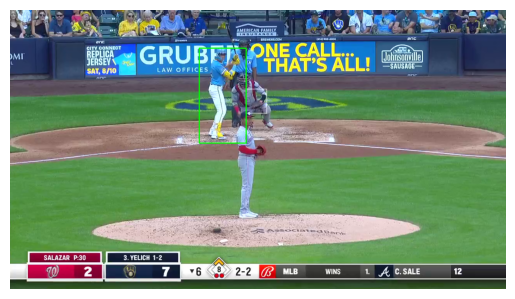

Source Image Updated to 745965_710290c7-dba3-4807-a287-c0914b282101-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745965_710290c7-dba3-4807-a287-c0914b282101-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1148.6ms
Speed: 8.1ms preprocess, 1148.6ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     540.18      213.09       124.2      266.17]]
Class Value: [          0] 

[[     645.92      238.01      116.18      169.35]]
Class Value: [          2] 

[[     606.68      407.55      123.68      306.57]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745965_710290c7-dba3-4807-a287-c0914b282101-00000.jpg


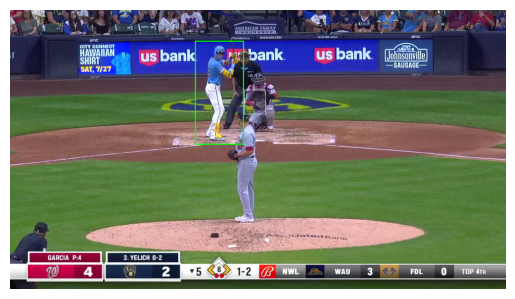

Source Image Updated to 745965_b248393f-e8cc-48f7-8235-d08e53962c7d-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745965_b248393f-e8cc-48f7-8235-d08e53962c7d-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1231.8ms
Speed: 8.7ms preprocess, 1231.8ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     543.71      214.49      128.99      267.84]]
Class Value: [          0] 

[[     637.86      244.49      119.16      163.86]]
Class Value: [          2] 

[[      610.6      408.18      122.02      320.02]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745965_b248393f-e8cc-48f7-8235-d08e53962c7d-00000.jpg


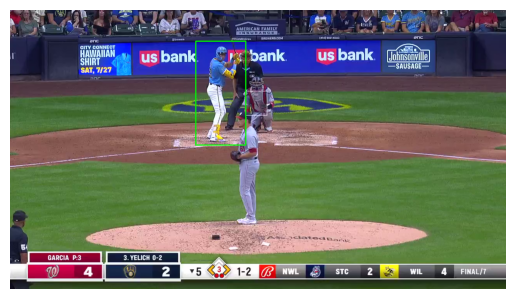

Source Image Updated to 745965_f701bf4d-27c3-48cf-8dab-430bb199292b-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745965_f701bf4d-27c3-48cf-8dab-430bb199292b-00000.png: 480x800 (no detections), 1204.6ms
Speed: 9.2ms preprocess, 1204.6ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


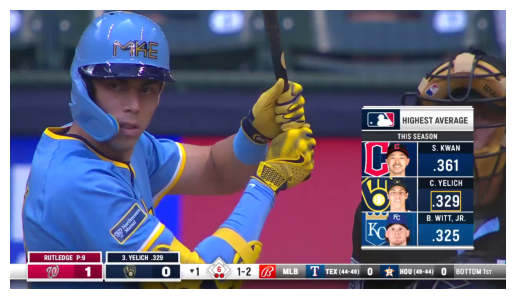

Source Image Updated to 745967_4966e868-aaf8-406b-96d2-f675e8766bb3-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745967_4966e868-aaf8-406b-96d2-f675e8766bb3-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1173.0ms
Speed: 7.7ms preprocess, 1173.0ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[      547.2       208.9      119.92      275.54]]
Class Value: [          0] 

[[     644.35      239.64      122.21      168.48]]
Class Value: [          2] 

[[     625.51      395.53      139.61      343.55]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745967_4966e868-aaf8-406b-96d2-f675e8766bb3-00000.jpg


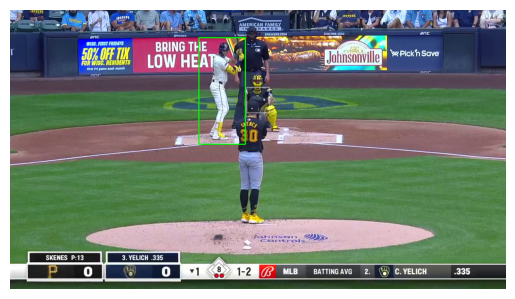

Source Image Updated to 745967_9c754b8f-b521-42fb-9268-8c781088f5fe-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745967_9c754b8f-b521-42fb-9268-8c781088f5fe-00000.png: 480x800 (no detections), 1241.2ms
Speed: 8.3ms preprocess, 1241.2ms inference, 0.7ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


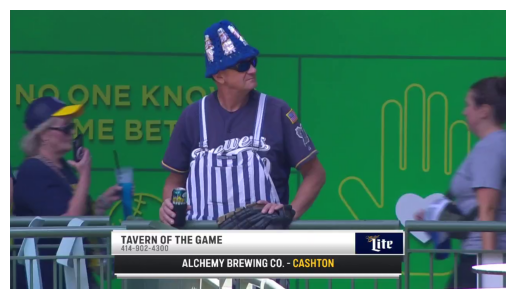

Source Image Updated to 745967_ce1c2516-542a-41ae-b1da-06b93497ee0a-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745967_ce1c2516-542a-41ae-b1da-06b93497ee0a-00000.png: 480x800 (no detections), 1236.4ms
Speed: 8.0ms preprocess, 1236.4ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


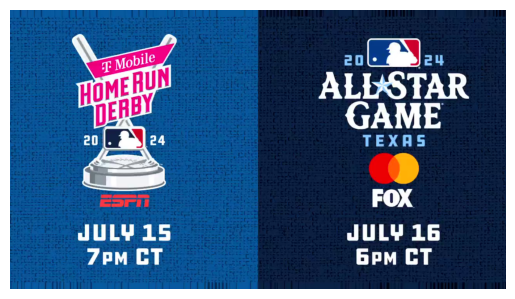

Source Image Updated to 745968_4c8db86e-f2b8-4a0e-809b-686d1e5d5bed-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745968_4c8db86e-f2b8-4a0e-809b-686d1e5d5bed-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1254.9ms
Speed: 7.1ms preprocess, 1254.9ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     587.63      393.36      123.17      309.39]]
Class Value: [          1] 

[[     541.83      205.83      114.28      260.49]]
Class Value: [          0] 

[[      642.7      231.62      124.81      164.49]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745968_4c8db86e-f2b8-4a0e-809b-686d1e5d5bed-00000.jpg


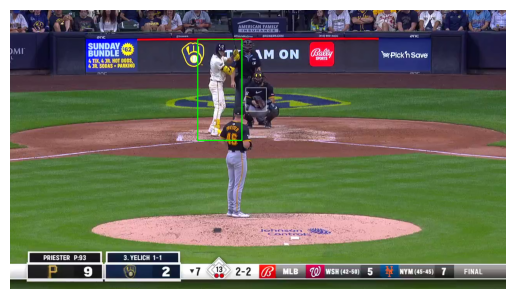

Source Image Updated to 745969_12092f34-6dd8-41a2-ba96-2dffc1dec0fc-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745969_12092f34-6dd8-41a2-ba96-2dffc1dec0fc-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1293.7ms
Speed: 7.4ms preprocess, 1293.7ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     550.32         217      124.22      266.23]]
Class Value: [          0] 

[[      594.3      420.49      146.99      291.69]]
Class Value: [          1] 

[[     653.53      244.46      122.41      171.66]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745969_12092f34-6dd8-41a2-ba96-2dffc1dec0fc-00000.jpg


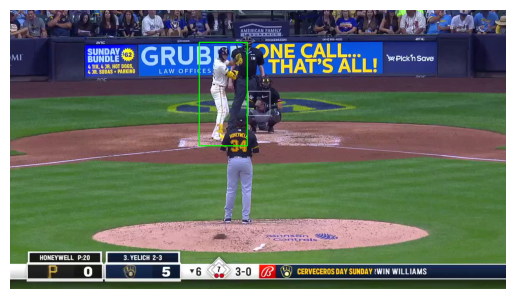

Source Image Updated to 745969_5c2c5eae-554f-43d0-9736-c7c5f2a1ec9e-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745969_5c2c5eae-554f-43d0-9736-c7c5f2a1ec9e-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1255.4ms
Speed: 9.2ms preprocess, 1255.4ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     555.14      216.28      123.55      266.04]]
Class Value: [          0] 

[[     643.02      240.07      138.64      170.19]]
Class Value: [          2] 

[[     596.28      412.22      140.98      305.32]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745969_5c2c5eae-554f-43d0-9736-c7c5f2a1ec9e-00000.jpg


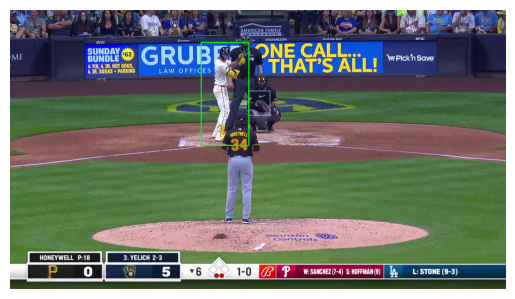

Source Image Updated to 745970_4d4676d7-e6b3-4d5d-94e8-efae4e7fc1c8-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745970_4d4676d7-e6b3-4d5d-94e8-efae4e7fc1c8-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1232.2ms
Speed: 7.6ms preprocess, 1232.2ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     554.43       247.1      125.76      257.98]]
Class Value: [          0] 

[[     670.57      275.31      124.44      156.26]]
Class Value: [          2] 

[[     634.39      430.59      125.63      311.64]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745970_4d4676d7-e6b3-4d5d-94e8-efae4e7fc1c8-00000.jpg


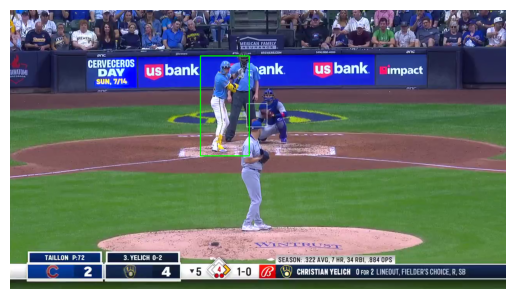

Source Image Updated to 745970_89d88fb2-f941-446e-8802-01a9efa185ba-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745970_89d88fb2-f941-446e-8802-01a9efa185ba-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1221.0ms
Speed: 9.1ms preprocess, 1221.0ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     554.69      247.91      115.98      256.35]]
Class Value: [          0] 

[[     634.55      276.68      110.93      165.12]]
Class Value: [          2] 

[[     635.97      431.64      123.49      307.91]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745970_89d88fb2-f941-446e-8802-01a9efa185ba-00000.jpg


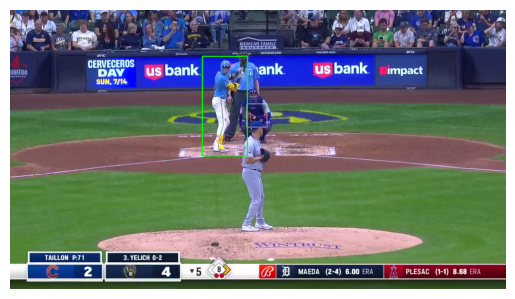

Source Image Updated to 745970_b84cc5bb-e1dc-45cf-8beb-52dbe528e2db-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745970_b84cc5bb-e1dc-45cf-8beb-52dbe528e2db-00000.png: 480x800 (no detections), 1204.8ms
Speed: 9.2ms preprocess, 1204.8ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


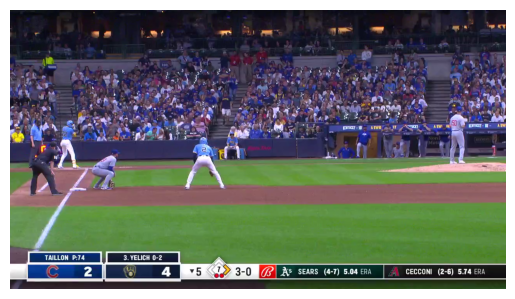

Source Image Updated to 745971_0fb977c9-90de-418a-8682-50d52c407034-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745971_0fb977c9-90de-418a-8682-50d52c407034-00000.png: 480x800 (no detections), 1184.9ms
Speed: 6.4ms preprocess, 1184.9ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


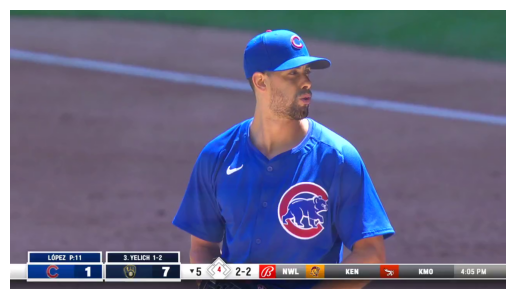

Source Image Updated to 745971_52aca2b6-360a-4974-b912-b581c0111ed4-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745971_52aca2b6-360a-4974-b912-b581c0111ed4-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1133.9ms
Speed: 6.4ms preprocess, 1133.9ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[      633.2      261.05      107.61      156.67]]
Class Value: [          2] 

[[     624.08       423.7      133.96      297.33]]
Class Value: [          1] 

[[        550       238.7      121.14      254.98]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745971_52aca2b6-360a-4974-b912-b581c0111ed4-00000.jpg


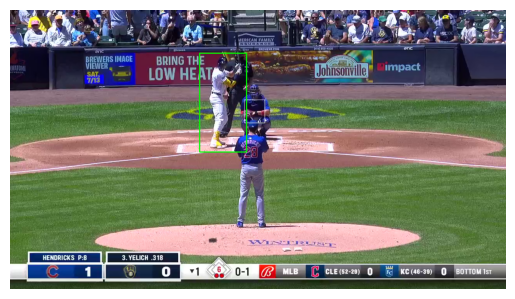

Source Image Updated to 745971_abea6f4a-542a-4b3e-8bd0-5a675a78bb7b-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745971_abea6f4a-542a-4b3e-8bd0-5a675a78bb7b-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1102.5ms
Speed: 8.0ms preprocess, 1102.5ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     472.06      334.31      72.423      104.74]]
Class Value: [          2] 

[[     417.51      318.19      72.765      167.67]]
Class Value: [          0] 

[[     460.74      438.18      73.421       194.9]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745971_abea6f4a-542a-4b3e-8bd0-5a675a78bb7b-00000.jpg


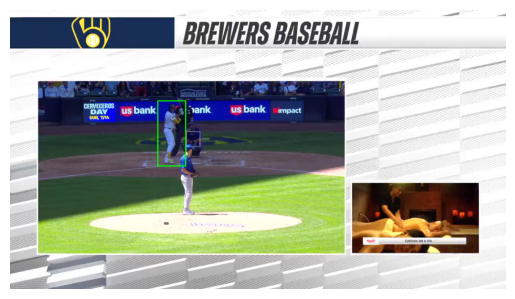

Source Image Updated to 745972_0607e3dd-b96d-4236-ac25-d60d2b863975-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745972_0607e3dd-b96d-4236-ac25-d60d2b863975-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1088.6ms
Speed: 7.5ms preprocess, 1088.6ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     633.24      280.62       113.5      158.27]]
Class Value: [          2] 

[[     549.09      255.59      109.42      254.84]]
Class Value: [          0] 

[[     661.21       432.2      120.52      304.31]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745972_0607e3dd-b96d-4236-ac25-d60d2b863975-00000.jpg


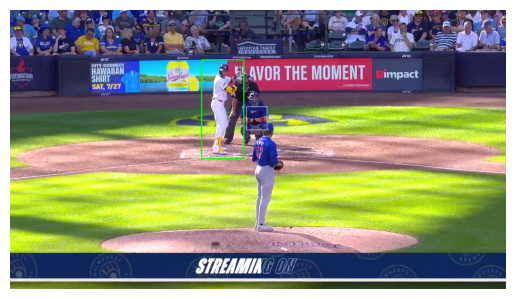

Source Image Updated to 745972_22cf0df8-8607-4700-aabd-f3656944fe3c-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745972_22cf0df8-8607-4700-aabd-f3656944fe3c-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1122.4ms
Speed: 6.7ms preprocess, 1122.4ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     550.24      250.61      111.19      254.92]]
Class Value: [          0] 

[[     639.26      275.24      103.01      154.74]]
Class Value: [          2] 

[[     659.78      427.33      121.13      305.36]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745972_22cf0df8-8607-4700-aabd-f3656944fe3c-00000.jpg


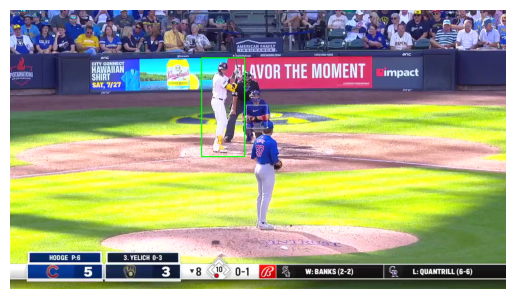

Source Image Updated to 745972_5287c427-d917-428d-903d-8d4b607c690f-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745972_5287c427-d917-428d-903d-8d4b607c690f-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1124.8ms
Speed: 8.4ms preprocess, 1124.8ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     548.69      252.61      117.75      254.65]]
Class Value: [          0] 

[[     654.43      429.09      122.56      305.98]]
Class Value: [          1] 

[[     630.81      277.48         109       158.7]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745972_5287c427-d917-428d-903d-8d4b607c690f-00000.jpg


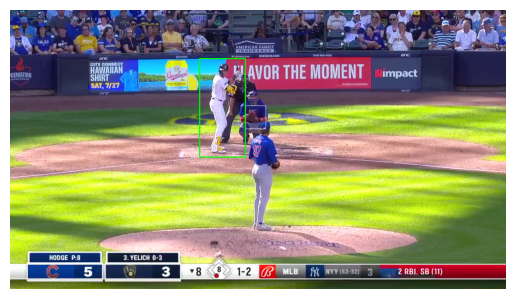

Source Image Updated to 745973_0c268a32-dce6-4308-9138-75c759ca7dd6-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745973_0c268a32-dce6-4308-9138-75c759ca7dd6-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1104.0ms
Speed: 6.9ms preprocess, 1104.0ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     651.67      274.76      123.64       150.5]]
Class Value: [          2] 

[[     559.31      243.08      117.81      255.72]]
Class Value: [          0] 

[[     648.68      427.47      124.55      285.23]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745973_0c268a32-dce6-4308-9138-75c759ca7dd6-00000.jpg


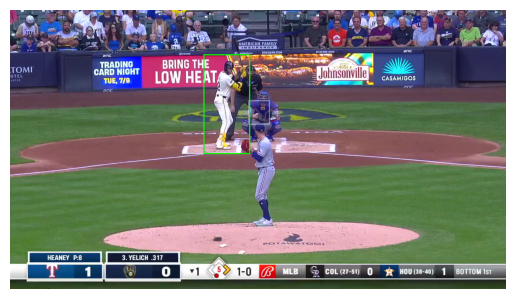

Source Image Updated to 745973_346094d5-8a77-4488-8c3e-23b47bc35df9-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745973_346094d5-8a77-4488-8c3e-23b47bc35df9-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1125.2ms
Speed: 5.2ms preprocess, 1125.2ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     636.32      266.77      122.47       153.2]]
Class Value: [          2] 

[[     554.16      238.18      124.34      256.07]]
Class Value: [          0] 

[[     640.94      430.18      130.41      290.43]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745973_346094d5-8a77-4488-8c3e-23b47bc35df9-00000.jpg


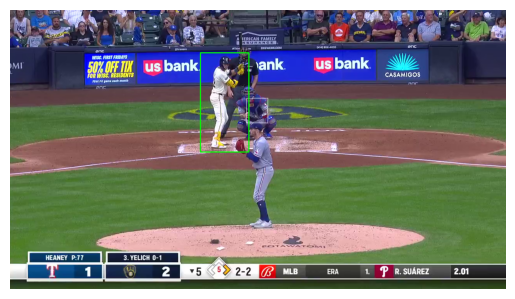

Source Image Updated to 745973_4ecf925f-c85b-4383-b876-de5d16ac765e-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745973_4ecf925f-c85b-4383-b876-de5d16ac765e-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1135.9ms
Speed: 6.1ms preprocess, 1135.9ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     556.17      238.26      117.82      256.12]]
Class Value: [          0] 

[[     639.91      269.52      119.73      149.82]]
Class Value: [          2] 

[[      648.4      426.63      129.83      290.71]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745973_4ecf925f-c85b-4383-b876-de5d16ac765e-00000.jpg


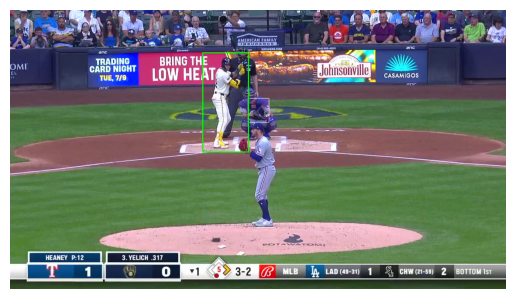

Source Image Updated to 745974_843b52ee-560f-417b-8422-11f7357d6809-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745974_843b52ee-560f-417b-8422-11f7357d6809-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1226.6ms
Speed: 7.5ms preprocess, 1226.6ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     638.61      267.78      122.86      157.54]]
Class Value: [          2] 

[[     553.02      242.25       122.4      256.39]]
Class Value: [          0] 

[[     650.55       427.3      115.89      307.31]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745974_843b52ee-560f-417b-8422-11f7357d6809-00000.jpg


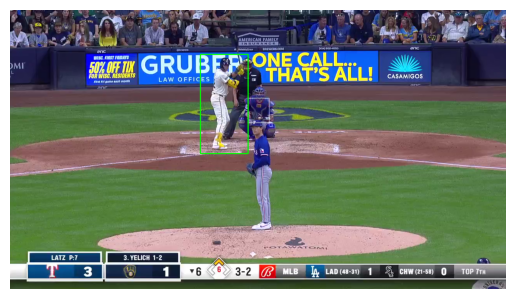

Source Image Updated to 745974_d57963ba-a81a-4de5-8e97-4e9f6beb8b74-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745974_d57963ba-a81a-4de5-8e97-4e9f6beb8b74-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1231.6ms
Speed: 9.5ms preprocess, 1231.6ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     658.19      272.94      121.95       147.6]]
Class Value: [          2] 

[[     557.67      239.49      122.06      262.93]]
Class Value: [          0] 

[[     650.34       431.5      116.58      300.38]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745974_d57963ba-a81a-4de5-8e97-4e9f6beb8b74-00000.jpg


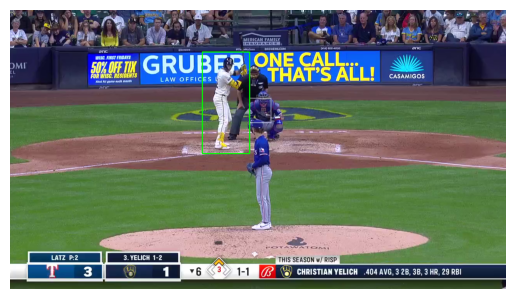

Source Image Updated to 745974_e5cd08b8-2510-4fba-aa41-ea1592682cc3-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745974_e5cd08b8-2510-4fba-aa41-ea1592682cc3-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1258.5ms
Speed: 8.1ms preprocess, 1258.5ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     660.97      267.17      120.34      156.03]]
Class Value: [          2] 

[[     558.28      241.08      114.38      257.27]]
Class Value: [          0] 

[[     617.26      431.93      116.98       288.8]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745974_e5cd08b8-2510-4fba-aa41-ea1592682cc3-00000.jpg


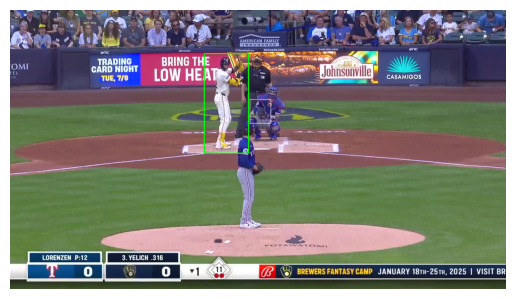

Source Image Updated to 745975_04558eaa-d2b3-403f-a36b-88b28878cc1f-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745975_04558eaa-d2b3-403f-a36b-88b28878cc1f-00000.png: 480x800 1 hitter, 1155.3ms
Speed: 6.2ms preprocess, 1155.3ms inference, 2.7ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     579.53      364.52      541.99       677.7]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745975_04558eaa-d2b3-403f-a36b-88b28878cc1f-00000.jpg


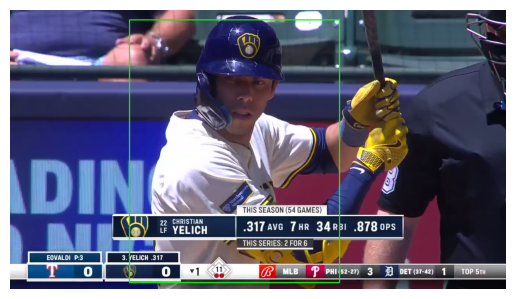

Source Image Updated to 745975_2d330a26-dfe5-4193-846c-a46bfedbce77-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745975_2d330a26-dfe5-4193-846c-a46bfedbce77-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1104.0ms
Speed: 7.9ms preprocess, 1104.0ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     621.88      270.43      132.37      147.36]]
Class Value: [          2] 

[[     633.22      429.57      126.22      291.95]]
Class Value: [          1] 

[[     554.74      241.85      108.68      254.34]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745975_2d330a26-dfe5-4193-846c-a46bfedbce77-00000.jpg


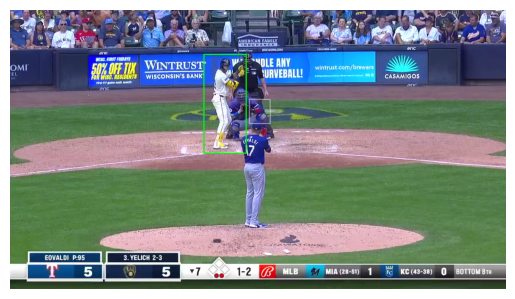

Source Image Updated to 745975_7894a7b8-1a53-46fe-a363-c78ec0d6f8cb-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745975_7894a7b8-1a53-46fe-a363-c78ec0d6f8cb-00000.png: 480x800 (no detections), 1105.2ms
Speed: 8.4ms preprocess, 1105.2ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


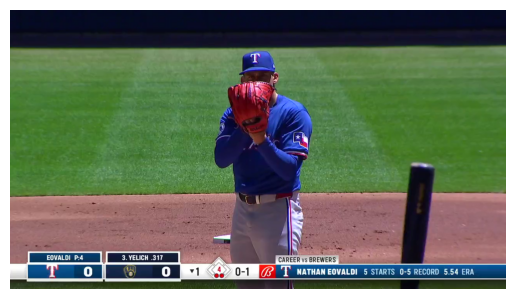

Source Image Updated to 745976_1f894b0c-f8f5-42a1-a81a-3cebb881cfba-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745976_1f894b0c-f8f5-42a1-a81a-3cebb881cfba-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1256.4ms
Speed: 8.1ms preprocess, 1256.4ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     550.52      246.01      120.55      255.17]]
Class Value: [          0] 

[[     647.39      266.19      114.96       163.3]]
Class Value: [          2] 

[[     683.72      431.39      119.49      285.58]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745976_1f894b0c-f8f5-42a1-a81a-3cebb881cfba-00000.jpg


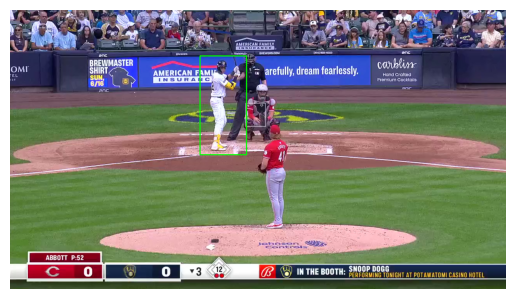

Source Image Updated to 745976_bf20a583-76ea-4886-b137-d5a3b1cde6ac-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745976_bf20a583-76ea-4886-b137-d5a3b1cde6ac-00000.png: 480x800 (no detections), 1288.6ms
Speed: 6.7ms preprocess, 1288.6ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


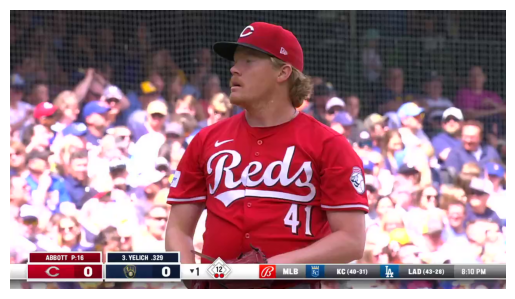

Source Image Updated to 745976_d3e41aeb-26f7-4f8e-9215-2effe7acb810-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745976_d3e41aeb-26f7-4f8e-9215-2effe7acb810-00000.png: 480x800 (no detections), 1215.2ms
Speed: 8.0ms preprocess, 1215.2ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


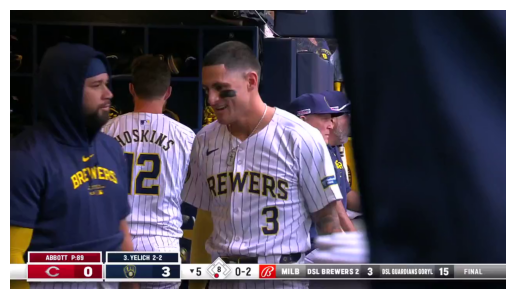

Source Image Updated to 745977_2b7433a5-1e13-4504-8f44-1cb7a26e2f7d-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745977_2b7433a5-1e13-4504-8f44-1cb7a26e2f7d-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1167.4ms
Speed: 6.8ms preprocess, 1167.4ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     603.05      427.87      133.71      285.65]]
Class Value: [          1] 

[[     566.86      251.31      119.42      243.51]]
Class Value: [          0] 

[[     621.13      274.12      134.18      150.05]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745977_2b7433a5-1e13-4504-8f44-1cb7a26e2f7d-00000.jpg


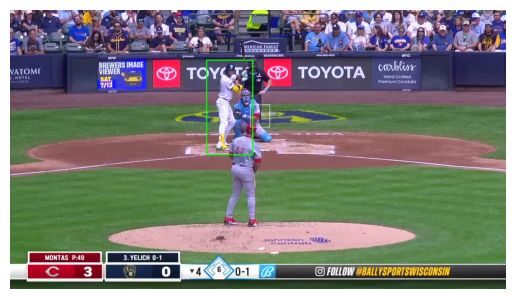

Source Image Updated to 745977_3d3b9e84-b680-4d5e-b4d0-ed60a816008c-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745977_3d3b9e84-b680-4d5e-b4d0-ed60a816008c-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1220.1ms
Speed: 7.8ms preprocess, 1220.1ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     634.63      255.02      119.46      173.08]]
Class Value: [          2] 

[[     552.24      238.88      121.97      262.93]]
Class Value: [          0] 

[[     604.39      434.17      126.39      301.96]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745977_3d3b9e84-b680-4d5e-b4d0-ed60a816008c-00000.jpg


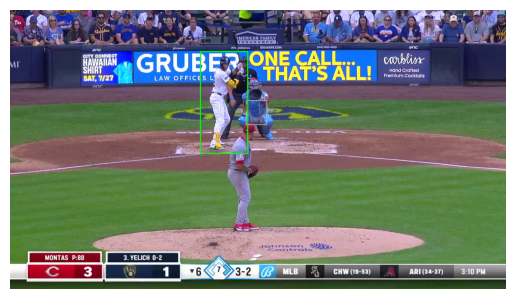

Source Image Updated to 745977_ec88a987-836b-4560-aa5e-39fecfa47643-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745977_ec88a987-836b-4560-aa5e-39fecfa47643-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1360.6ms
Speed: 9.0ms preprocess, 1360.6ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     629.89      265.42      145.13      157.55]]
Class Value: [          2] 

[[     604.48       434.7      121.87      290.37]]
Class Value: [          1] 

[[     546.51      244.44      112.61      255.63]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745977_ec88a987-836b-4560-aa5e-39fecfa47643-00000.jpg


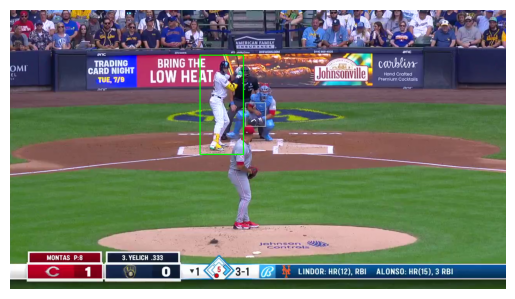

Source Image Updated to 745979_46b05a27-dc74-4848-9159-27f70c160710-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745979_46b05a27-dc74-4848-9159-27f70c160710-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1262.3ms
Speed: 5.7ms preprocess, 1262.3ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[        653      257.27      118.41      177.93]]
Class Value: [          2] 

[[      554.4      241.95      128.25       261.5]]
Class Value: [          0] 

[[     640.84      434.72      125.81      299.34]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745979_46b05a27-dc74-4848-9159-27f70c160710-00000.jpg


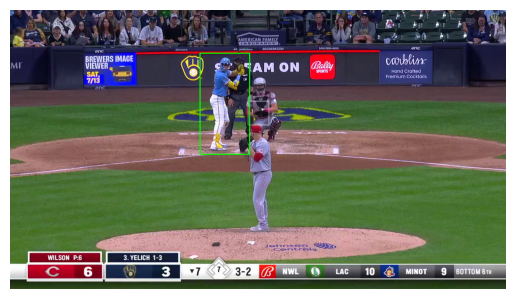

Source Image Updated to 745979_b4a439cc-dd70-4ff6-853e-af14504578d5-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745979_b4a439cc-dd70-4ff6-853e-af14504578d5-00000.png: 480x800 1 pitcher, 1217.7ms
Speed: 8.8ms preprocess, 1217.7ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     565.84      329.52      253.14      571.21]]
Class Value: [          1] 



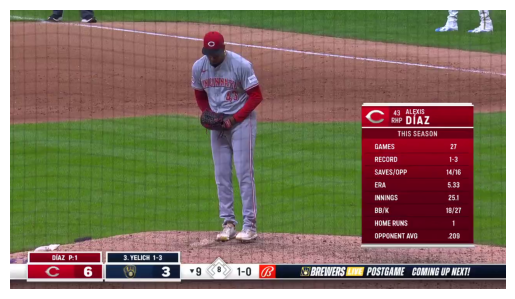

Source Image Updated to 745979_caf3fe56-1ecc-411c-a205-2026f410c687-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745979_caf3fe56-1ecc-411c-a205-2026f410c687-00000.png: 480x800 1 hitter, 1212.5ms
Speed: 7.3ms preprocess, 1212.5ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     698.46      392.59      623.58      654.82]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745979_caf3fe56-1ecc-411c-a205-2026f410c687-00000.jpg


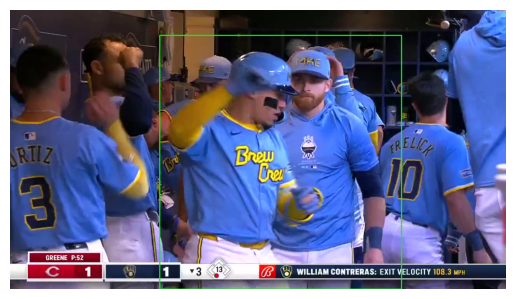

Source Image Updated to 745980_41061cf0-d3f9-43e5-b4f0-5713186b0aca-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745980_41061cf0-d3f9-43e5-b4f0-5713186b0aca-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1264.0ms
Speed: 8.2ms preprocess, 1264.0ms inference, 2.3ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     553.82      249.29      118.08      248.96]]
Class Value: [          0] 

[[     637.73      266.79      116.08      160.37]]
Class Value: [          2] 

[[        663      424.39      121.37      292.57]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745980_41061cf0-d3f9-43e5-b4f0-5713186b0aca-00000.jpg


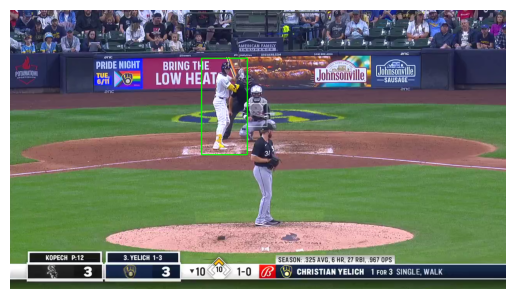

Source Image Updated to 745980_c75d10c7-07be-426b-8a11-5a65dddc9cb9-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745980_c75d10c7-07be-426b-8a11-5a65dddc9cb9-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1228.9ms
Speed: 6.6ms preprocess, 1228.9ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     653.42      255.88      111.07      188.46]]
Class Value: [          2] 

[[     555.25      238.59      125.85      264.94]]
Class Value: [          0] 

[[     671.16      421.81      127.97      321.99]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745980_c75d10c7-07be-426b-8a11-5a65dddc9cb9-00000.jpg


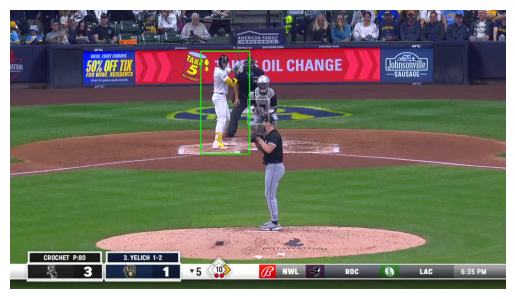

Source Image Updated to 745980_d884d43d-7ac8-4039-90fd-130b25a5b0b2-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745980_d884d43d-7ac8-4039-90fd-130b25a5b0b2-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1304.5ms
Speed: 6.7ms preprocess, 1304.5ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     691.31      419.26       141.9      324.82]]
Class Value: [          1] 

[[     551.86      240.62       115.8      263.92]]
Class Value: [          0] 

[[     642.24      264.64      122.55      161.31]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745980_d884d43d-7ac8-4039-90fd-130b25a5b0b2-00000.jpg


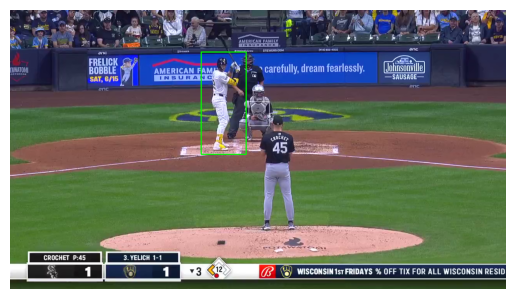

Source Image Updated to 745981_49804b1e-a5c3-49e6-9153-ed0fc47e9149-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745981_49804b1e-a5c3-49e6-9153-ed0fc47e9149-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1176.8ms
Speed: 8.4ms preprocess, 1176.8ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     635.53      256.63       133.5      162.84]]
Class Value: [          2] 

[[     662.49      426.72      128.55      304.43]]
Class Value: [          1] 

[[     545.81      232.74      117.83      264.82]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745981_49804b1e-a5c3-49e6-9153-ed0fc47e9149-00000.jpg


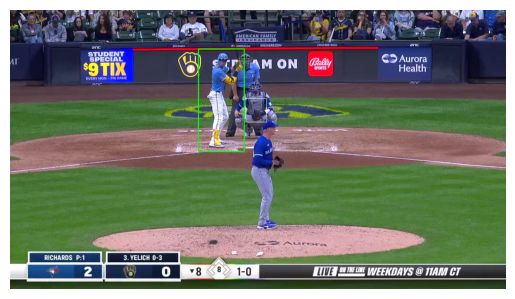

Source Image Updated to 745981_6d90c927-26ce-4218-8de3-a3a239e8b089-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745981_6d90c927-26ce-4218-8de3-a3a239e8b089-00000.png: 480x800 (no detections), 1208.9ms
Speed: 8.6ms preprocess, 1208.9ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


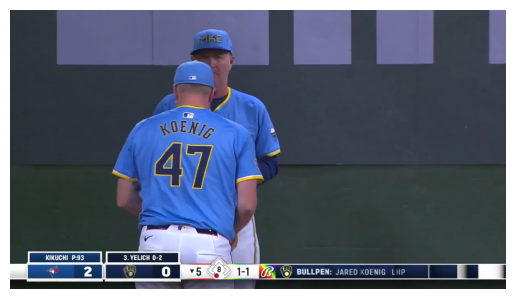

Source Image Updated to 745981_9d8cfc17-2b15-4329-8a1a-8e4c9822c298-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745981_9d8cfc17-2b15-4329-8a1a-8e4c9822c298-00000.png: 480x800 1 hitter, 1218.5ms
Speed: 7.7ms preprocess, 1218.5ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     806.31      395.87      709.84      641.88]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745981_9d8cfc17-2b15-4329-8a1a-8e4c9822c298-00000.jpg


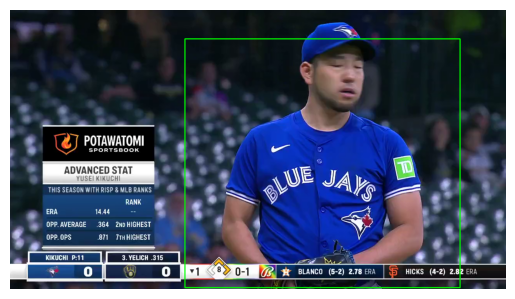

Source Image Updated to 745982_2902c1dc-aeb8-4122-acd4-a77d9cc3cff2-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745982_2902c1dc-aeb8-4122-acd4-a77d9cc3cff2-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1252.0ms
Speed: 6.1ms preprocess, 1252.0ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     643.63      254.73      127.65      160.48]]
Class Value: [          2] 

[[     555.48      231.87      128.63      263.85]]
Class Value: [          0] 

[[     626.89      431.87      118.72      304.73]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745982_2902c1dc-aeb8-4122-acd4-a77d9cc3cff2-00000.jpg


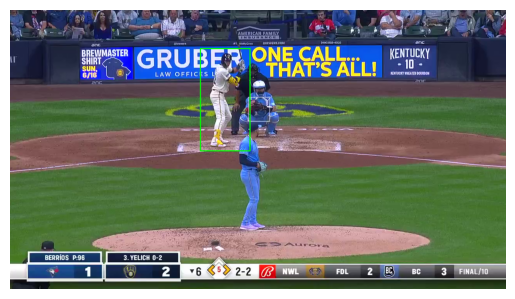

Source Image Updated to 745982_c65fcaa1-dd6f-45f5-ac70-d1d2ab14808f-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745982_c65fcaa1-dd6f-45f5-ac70-d1d2ab14808f-00000.png: 480x800 (no detections), 1178.1ms
Speed: 7.5ms preprocess, 1178.1ms inference, 1.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


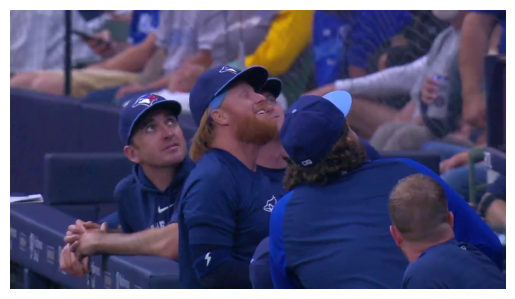

Source Image Updated to 745982_f5814d75-9b92-4970-88c9-1e3a5c77dba4-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745982_f5814d75-9b92-4970-88c9-1e3a5c77dba4-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1216.0ms
Speed: 7.9ms preprocess, 1216.0ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     649.03      263.89      123.44      165.69]]
Class Value: [          2] 

[[     550.09      242.25      114.13      257.92]]
Class Value: [          0] 

[[     623.41      434.24      117.21      296.27]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745982_f5814d75-9b92-4970-88c9-1e3a5c77dba4-00000.jpg


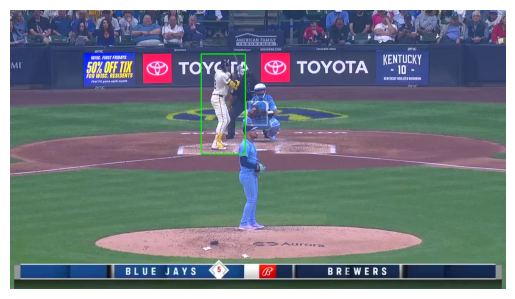

Source Image Updated to 745983_e2a17454-b5c5-496b-9f0f-8e2d3a840e91-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745983_e2a17454-b5c5-496b-9f0f-8e2d3a840e91-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1290.8ms
Speed: 9.0ms preprocess, 1290.8ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     649.99      263.52      120.33      165.09]]
Class Value: [          2] 

[[     564.26       237.3      122.61      261.65]]
Class Value: [          0] 

[[     650.58      432.54      123.21       301.7]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745983_e2a17454-b5c5-496b-9f0f-8e2d3a840e91-00000.jpg


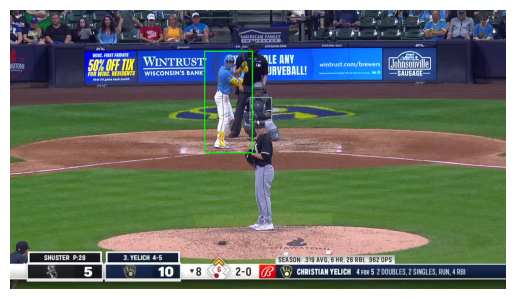

Source Image Updated to 745983_e319793c-a4ac-435d-b8da-38b043372a34-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745983_e319793c-a4ac-435d-b8da-38b043372a34-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1233.0ms
Speed: 12.1ms preprocess, 1233.0ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     553.13      242.47      121.67      258.74]]
Class Value: [          0] 

[[     672.55      433.71      132.59      291.61]]
Class Value: [          1] 

[[     637.42      265.12      104.29       163.6]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745983_e319793c-a4ac-435d-b8da-38b043372a34-00000.jpg


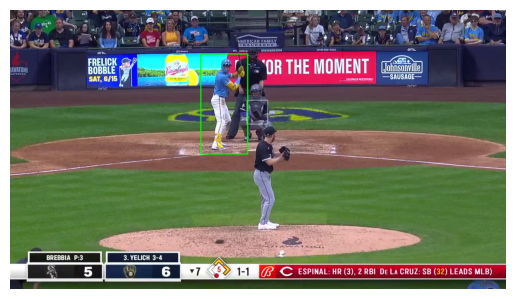

Source Image Updated to 745984_053748d8-e157-4503-b901-2610fa61b9d0-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745984_053748d8-e157-4503-b901-2610fa61b9d0-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1299.1ms
Speed: 7.9ms preprocess, 1299.1ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     677.68      259.67      140.57      188.98]]
Class Value: [          2] 

[[     561.69      249.51      121.56      248.53]]
Class Value: [          0] 

[[     672.69       426.5       147.5      296.98]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745984_053748d8-e157-4503-b901-2610fa61b9d0-00000.jpg


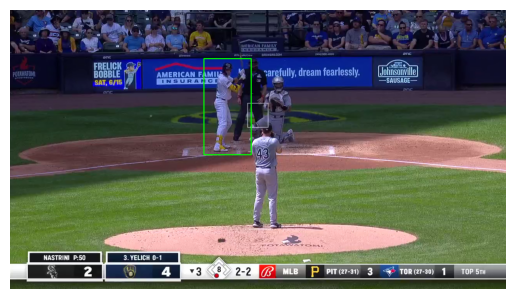

Source Image Updated to 745984_fbbdde22-f2db-4769-a8c0-0671e1521e7c-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745984_fbbdde22-f2db-4769-a8c0-0671e1521e7c-00000.png: 480x800 (no detections), 1233.2ms
Speed: 9.1ms preprocess, 1233.2ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


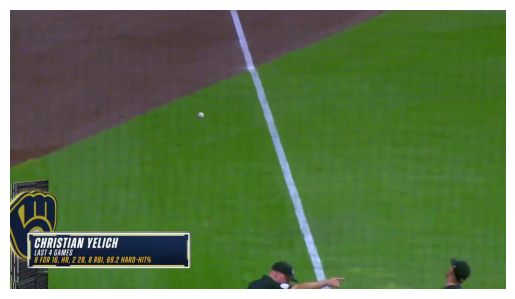

Source Image Updated to 745985_3a92abb7-27f9-4346-bbfa-5815520587fb-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745985_3a92abb7-27f9-4346-bbfa-5815520587fb-00000.png: 480x800 (no detections), 1296.0ms
Speed: 8.1ms preprocess, 1296.0ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


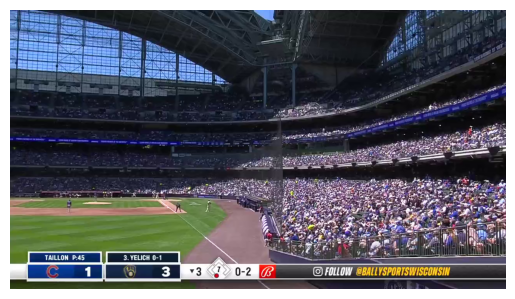

Source Image Updated to 745985_49ac63bc-63dd-4050-b079-50394e89739c-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745985_49ac63bc-63dd-4050-b079-50394e89739c-00000.png: 480x800 (no detections), 1259.5ms
Speed: 8.5ms preprocess, 1259.5ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


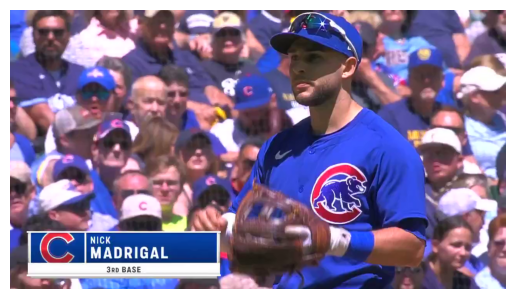

Source Image Updated to 745985_ad4fd6a8-bcf5-4033-9d24-a24fe31589d0-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745985_ad4fd6a8-bcf5-4033-9d24-a24fe31589d0-00000.png: 480x800 (no detections), 1262.5ms
Speed: 6.6ms preprocess, 1262.5ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


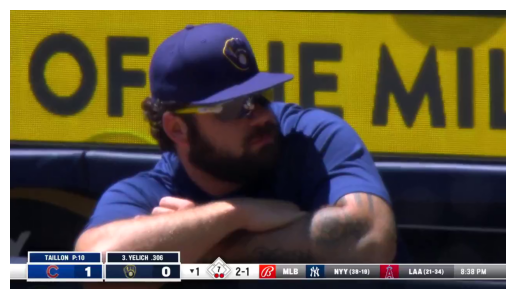

Source Image Updated to 745986_19935629-83f0-46b5-9169-0f59b9087884-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745986_19935629-83f0-46b5-9169-0f59b9087884-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1271.8ms
Speed: 6.8ms preprocess, 1271.8ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     636.87      265.93      111.17      160.62]]
Class Value: [          2] 

[[     548.56      239.52      123.04      267.18]]
Class Value: [          0] 

[[     663.26      431.35      123.59      300.67]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745986_19935629-83f0-46b5-9169-0f59b9087884-00000.jpg


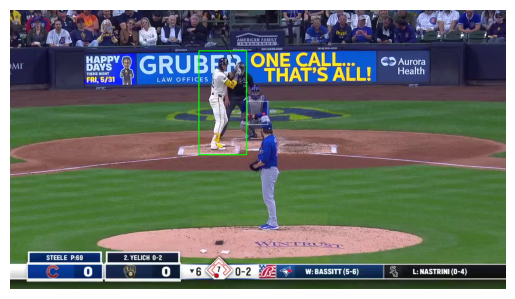

Source Image Updated to 745986_24a81add-8e25-403f-9a96-cac20d38b1e1-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745986_24a81add-8e25-403f-9a96-cac20d38b1e1-00000.png: 480x800 (no detections), 1266.0ms
Speed: 6.8ms preprocess, 1266.0ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


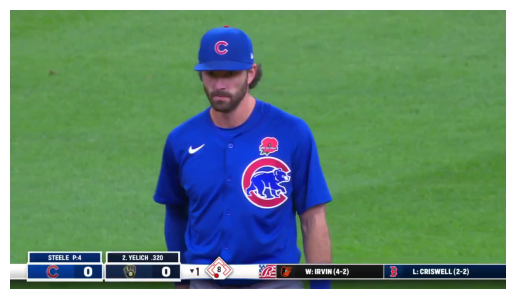

Source Image Updated to 745986_ae57daea-679f-4387-81e1-02f73743c870-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745986_ae57daea-679f-4387-81e1-02f73743c870-00000.png: 480x800 (no detections), 1204.0ms
Speed: 7.1ms preprocess, 1204.0ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


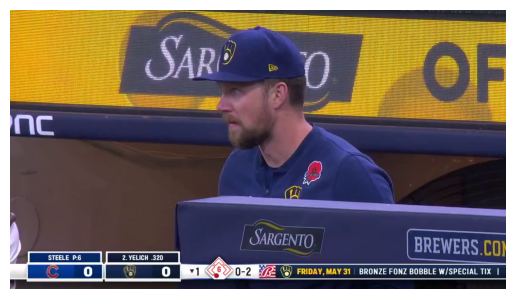

Source Image Updated to 745987_7a393ae8-e265-40a6-9bea-dc7e1a4f220b-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745987_7a393ae8-e265-40a6-9bea-dc7e1a4f220b-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1242.2ms
Speed: 7.1ms preprocess, 1242.2ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     558.99      224.41      138.27      280.47]]
Class Value: [          0] 

[[     638.93      256.47      137.95      167.13]]
Class Value: [          2] 

[[     624.85      417.01      142.99       346.2]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745987_7a393ae8-e265-40a6-9bea-dc7e1a4f220b-00000.jpg


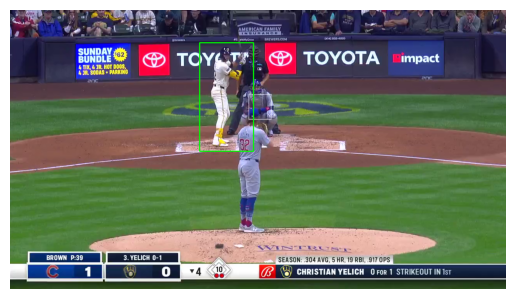

Source Image Updated to 745987_cd68e113-195f-43ef-9793-28db54d39dc7-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745987_cd68e113-195f-43ef-9793-28db54d39dc7-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1326.1ms
Speed: 6.8ms preprocess, 1326.1ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     638.23      237.67      145.89      179.55]]
Class Value: [          2] 

[[      550.1      215.11      125.15      284.72]]
Class Value: [          0] 

[[     616.85      412.48      135.98      341.85]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745987_cd68e113-195f-43ef-9793-28db54d39dc7-00000.jpg


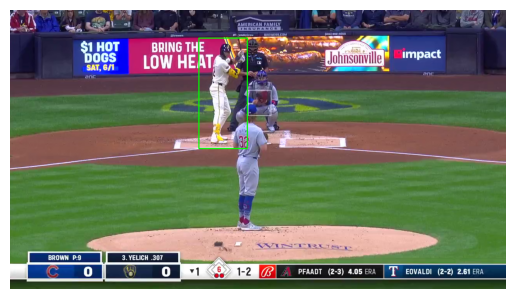

Source Image Updated to 745987_fa4764e7-6fd6-451c-bdff-c3d33bddd547-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745987_fa4764e7-6fd6-451c-bdff-c3d33bddd547-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1343.6ms
Speed: 8.6ms preprocess, 1343.6ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[      644.3      242.27       114.6      164.49]]
Class Value: [          2] 

[[     621.96      441.78      157.61       267.1]]
Class Value: [          1] 

[[     551.27      217.93       124.5      276.76]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745987_fa4764e7-6fd6-451c-bdff-c3d33bddd547-00000.jpg


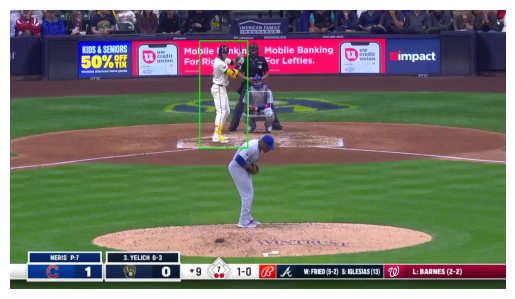

Source Image Updated to 745988_76d0f737-5df2-4aa7-b324-060cf23ffb87-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745988_76d0f737-5df2-4aa7-b324-060cf23ffb87-00000.png: 480x800 (no detections), 1313.4ms
Speed: 6.4ms preprocess, 1313.4ms inference, 0.7ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


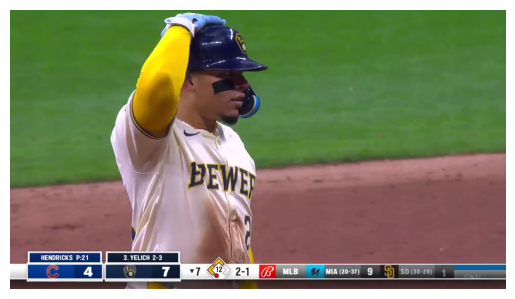

Source Image Updated to 745988_ae7ac817-f150-4cde-8fc0-f8aa04c0f41e-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745988_ae7ac817-f150-4cde-8fc0-f8aa04c0f41e-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1394.5ms
Speed: 6.3ms preprocess, 1394.5ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     635.64      256.28      126.08      167.48]]
Class Value: [          2] 

[[     541.24      224.03      132.25      290.96]]
Class Value: [          0] 

[[     614.05      440.91      125.85         316]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745988_ae7ac817-f150-4cde-8fc0-f8aa04c0f41e-00000.jpg


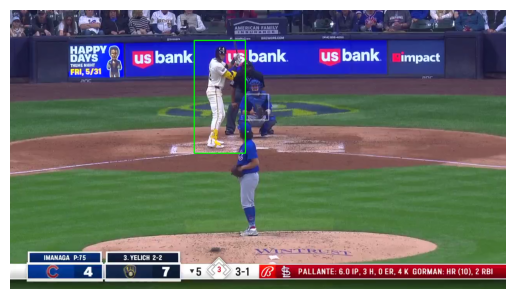

Source Image Updated to 745988_eb9307f8-213a-411e-87bc-1edb2216f456-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745988_eb9307f8-213a-411e-87bc-1edb2216f456-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1285.9ms
Speed: 6.4ms preprocess, 1285.9ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     651.14      244.19      137.96      166.96]]
Class Value: [          2] 

[[     556.37      217.56      129.13      274.82]]
Class Value: [          0] 

[[     626.17      423.68       123.2      305.13]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745988_eb9307f8-213a-411e-87bc-1edb2216f456-00000.jpg


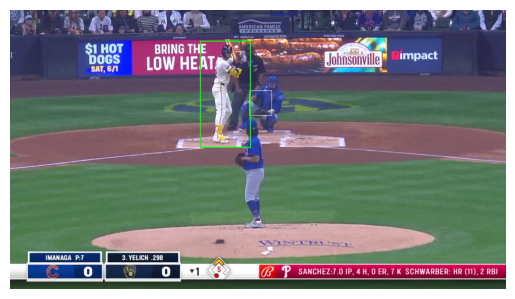

Source Image Updated to 745989_19bb7c48-8b8b-469d-864c-cdc5e375ff5f-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745989_19bb7c48-8b8b-469d-864c-cdc5e375ff5f-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1204.2ms
Speed: 6.0ms preprocess, 1204.2ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     560.24      223.95       127.7      271.15]]
Class Value: [          0] 

[[     657.52      247.96      122.43      175.51]]
Class Value: [          2] 

[[     622.99      419.61      122.85      316.37]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745989_19bb7c48-8b8b-469d-864c-cdc5e375ff5f-00000.jpg


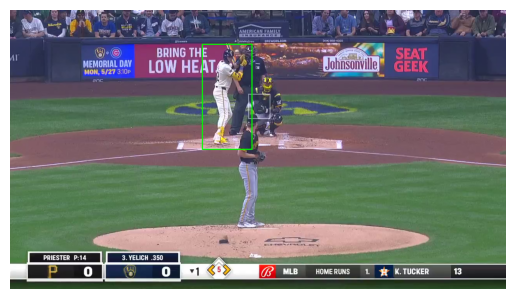

Source Image Updated to 745989_64745e97-1c5d-4d9c-807f-ae598eed051b-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745989_64745e97-1c5d-4d9c-807f-ae598eed051b-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1294.3ms
Speed: 8.5ms preprocess, 1294.3ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     544.46      217.69      132.12      282.72]]
Class Value: [          0] 

[[     645.01      251.28      136.14      169.71]]
Class Value: [          2] 

[[      596.1      423.72      131.01      315.69]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745989_64745e97-1c5d-4d9c-807f-ae598eed051b-00000.jpg


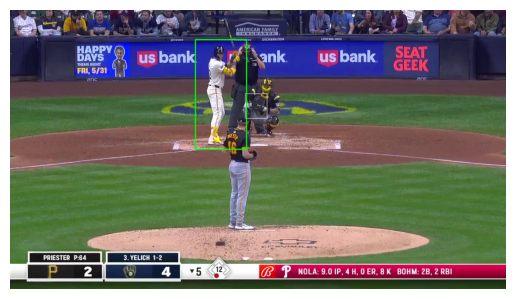

Source Image Updated to 745989_8ee73f72-b144-4312-be6f-152eb9b7e132-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745989_8ee73f72-b144-4312-be6f-152eb9b7e132-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1291.7ms
Speed: 8.5ms preprocess, 1291.7ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     649.36      252.74      134.79      180.85]]
Class Value: [          2] 

[[     555.02      223.89      129.16      280.07]]
Class Value: [          0] 

[[     649.94      430.11      127.33      316.58]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745989_8ee73f72-b144-4312-be6f-152eb9b7e132-00000.jpg


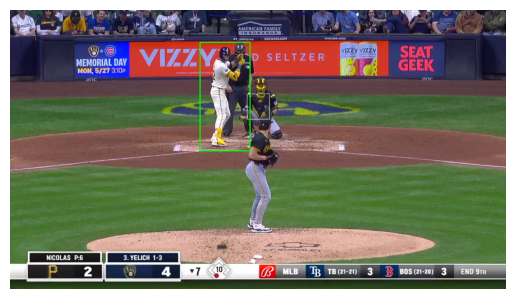

Source Image Updated to 745990_1674e687-9328-4eab-b825-b9e0e2402753-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745990_1674e687-9328-4eab-b825-b9e0e2402753-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1174.5ms
Speed: 6.3ms preprocess, 1174.5ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     637.72      245.81      139.42      176.16]]
Class Value: [          2] 

[[     651.66      425.53      155.92       326.2]]
Class Value: [          1] 

[[     533.54      216.23      133.15      288.71]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745990_1674e687-9328-4eab-b825-b9e0e2402753-00000.jpg


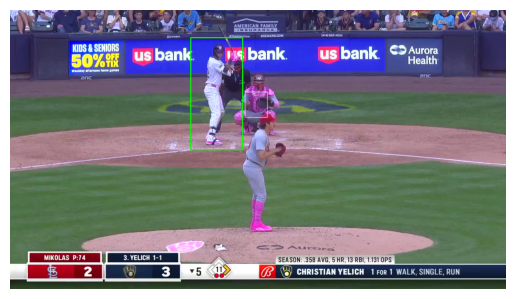

Source Image Updated to 745990_cb28c2a2-eeb2-480a-9d57-4788ff1cb0e9-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745990_cb28c2a2-eeb2-480a-9d57-4788ff1cb0e9-00000.png: 480x800 (no detections), 1170.4ms
Speed: 7.9ms preprocess, 1170.4ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


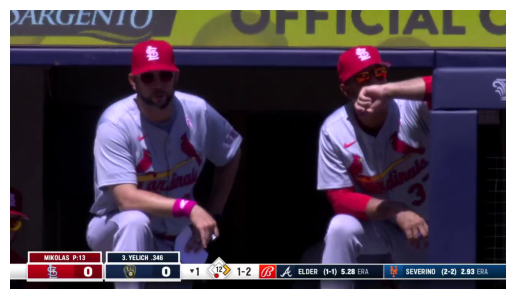

Source Image Updated to 745990_e2706b3d-239d-421f-bbc2-436bd0479050-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745990_e2706b3d-239d-421f-bbc2-436bd0479050-00000.png: 480x800 (no detections), 1145.6ms
Speed: 8.6ms preprocess, 1145.6ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


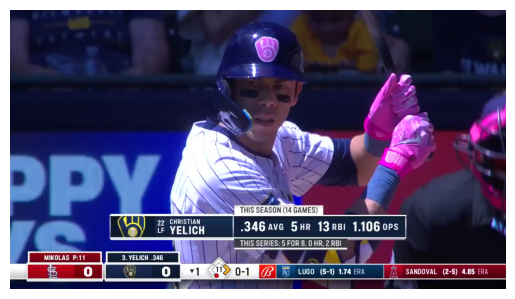

Source Image Updated to 745991_5a7bd8d8-f694-4655-b179-78376f6d79f8-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745991_5a7bd8d8-f694-4655-b179-78376f6d79f8-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1118.5ms
Speed: 6.2ms preprocess, 1118.5ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     535.86      220.85      130.28       289.3]]
Class Value: [          0] 

[[     628.82      422.63      153.43      343.58]]
Class Value: [          1] 

[[     639.58      254.07       138.3      170.84]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745991_5a7bd8d8-f694-4655-b179-78376f6d79f8-00000.jpg


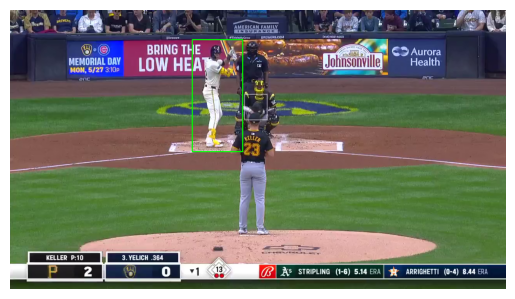

Source Image Updated to 745991_7fb896fc-a5f1-404e-abd6-54faf99b73ff-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745991_7fb896fc-a5f1-404e-abd6-54faf99b73ff-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1196.1ms
Speed: 6.8ms preprocess, 1196.1ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     550.66      215.29      135.37      282.23]]
Class Value: [          0] 

[[     646.09      247.33      128.12      177.31]]
Class Value: [          2] 

[[     649.28      414.19      119.73      335.67]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745991_7fb896fc-a5f1-404e-abd6-54faf99b73ff-00000.jpg


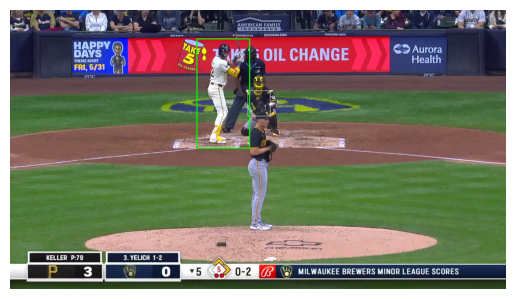

Source Image Updated to 745991_ebe634cf-ae52-4fb9-96aa-f4643f68454e-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745991_ebe634cf-ae52-4fb9-96aa-f4643f68454e-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1304.0ms
Speed: 7.0ms preprocess, 1304.0ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     548.08      226.13      127.76      272.43]]
Class Value: [          0] 

[[     636.42      253.47      132.91      182.54]]
Class Value: [          2] 

[[     638.92       426.2      117.41      331.33]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745991_ebe634cf-ae52-4fb9-96aa-f4643f68454e-00000.jpg


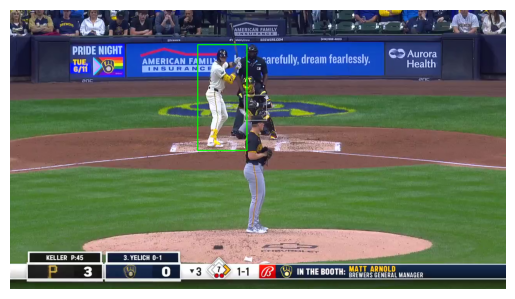

Source Image Updated to 745993_2923c78b-ef68-4e05-8e87-ee94fb5ce538-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745993_2923c78b-ef68-4e05-8e87-ee94fb5ce538-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1191.2ms
Speed: 6.5ms preprocess, 1191.2ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[      657.7      250.55      120.79      174.51]]
Class Value: [          2] 

[[     555.32      227.21      129.28      271.27]]
Class Value: [          0] 

[[      612.1      419.19      125.54      326.33]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745993_2923c78b-ef68-4e05-8e87-ee94fb5ce538-00000.jpg


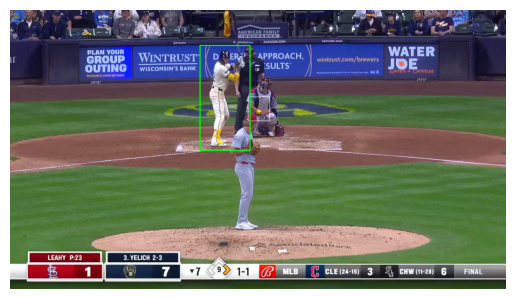

Source Image Updated to 745993_a1b4cc8b-ae74-42f9-8fa7-818735863678-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745993_a1b4cc8b-ae74-42f9-8fa7-818735863678-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1287.1ms
Speed: 6.7ms preprocess, 1287.1ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     665.44      244.43      130.96      178.13]]
Class Value: [          2] 

[[     555.93      220.52      133.85      278.94]]
Class Value: [          0] 

[[     618.54      416.86      124.15      342.41]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745993_a1b4cc8b-ae74-42f9-8fa7-818735863678-00000.jpg


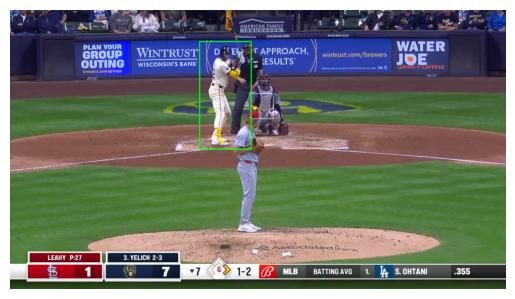

Source Image Updated to 745993_ec9656fa-c067-45d9-ba47-482b59eed5af-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745993_ec9656fa-c067-45d9-ba47-482b59eed5af-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1232.4ms
Speed: 7.8ms preprocess, 1232.4ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     554.26       226.8      131.31      268.83]]
Class Value: [          0] 

[[     662.35      249.76      121.27      170.58]]
Class Value: [          2] 

[[     611.42       419.1      124.49      323.11]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745993_ec9656fa-c067-45d9-ba47-482b59eed5af-00000.jpg


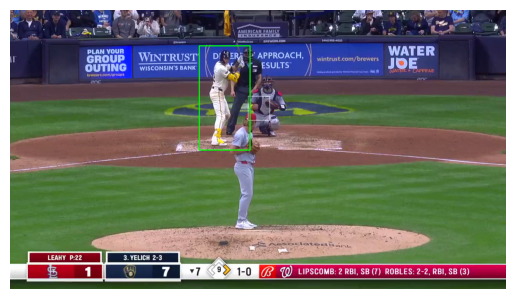

Source Image Updated to 745995_dd34b897-ce3e-469a-8ba4-ed47dcb9aac4-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745995_dd34b897-ce3e-469a-8ba4-ed47dcb9aac4-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1225.8ms
Speed: 6.9ms preprocess, 1225.8ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     642.85      272.04      156.84       164.1]]
Class Value: [          2] 

[[     557.26      242.21      124.97      263.95]]
Class Value: [          0] 

[[     618.51      437.79      115.83      289.16]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745995_dd34b897-ce3e-469a-8ba4-ed47dcb9aac4-00000.jpg


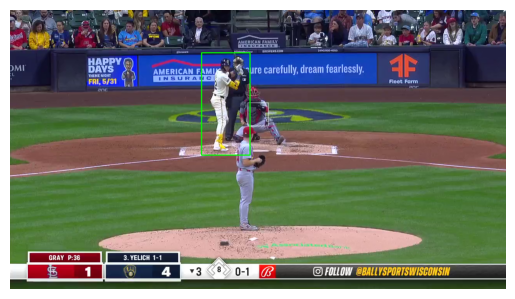

Source Image Updated to 745995_f54163e2-22a3-4814-82e5-f927367bc8e2-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\745995_f54163e2-22a3-4814-82e5-f927367bc8e2-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1317.9ms
Speed: 8.1ms preprocess, 1317.9ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     622.18      265.09      125.65      156.61]]
Class Value: [          2] 

[[     553.62      235.62      124.86      261.34]]
Class Value: [          0] 

[[     620.15      431.94      114.14      285.53]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_745995_f54163e2-22a3-4814-82e5-f927367bc8e2-00000.jpg


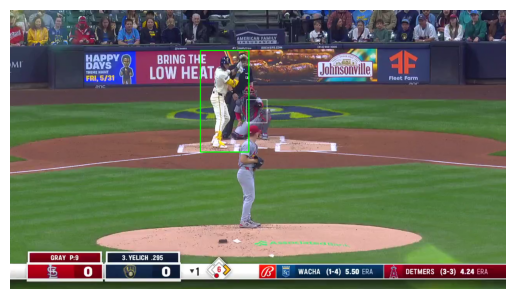

Source Image Updated to 746006_1b0913d2-8dc2-46db-9cf8-3bf3b407b0b3-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746006_1b0913d2-8dc2-46db-9cf8-3bf3b407b0b3-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1243.7ms
Speed: 7.1ms preprocess, 1243.7ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     627.74       239.9      134.93      187.91]]
Class Value: [          2] 

[[     539.67      222.15      140.49      284.47]]
Class Value: [          0] 

[[     603.52      430.58      127.32      330.67]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746006_1b0913d2-8dc2-46db-9cf8-3bf3b407b0b3-00000.jpg


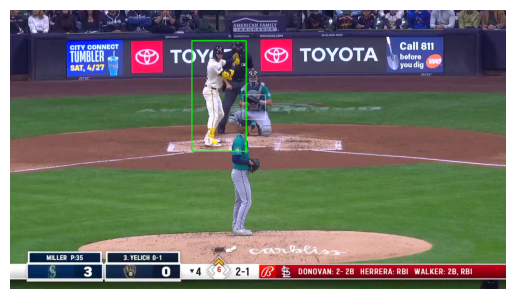

Source Image Updated to 746006_a81233fe-78fc-4597-abaf-510d36dbc292-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746006_a81233fe-78fc-4597-abaf-510d36dbc292-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1318.4ms
Speed: 7.2ms preprocess, 1318.4ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     632.29      249.04      127.53      165.97]]
Class Value: [          2] 

[[     537.85      220.98      138.99       285.5]]
Class Value: [          0] 

[[     603.55      435.21      124.04      323.17]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746006_a81233fe-78fc-4597-abaf-510d36dbc292-00000.jpg


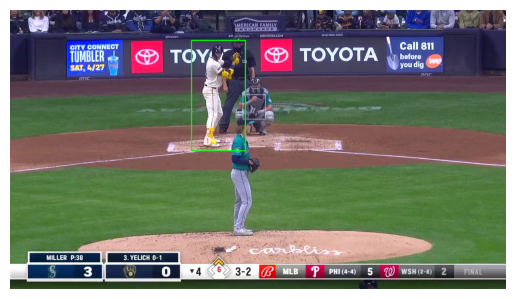

Source Image Updated to 746006_c3d1ba39-0cc4-4056-8ace-796c8f0845fc-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746006_c3d1ba39-0cc4-4056-8ace-796c8f0845fc-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1208.2ms
Speed: 6.6ms preprocess, 1208.2ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     650.18       246.5       121.1      163.71]]
Class Value: [          2] 

[[     633.57      433.26       126.4      312.89]]
Class Value: [          1] 

[[     546.12      223.42      118.02      277.81]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746006_c3d1ba39-0cc4-4056-8ace-796c8f0845fc-00000.jpg


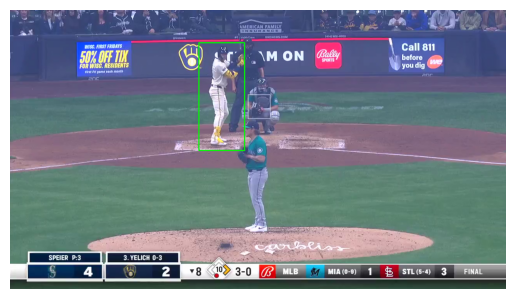

Source Image Updated to 746007_4f115ef6-a6db-4707-93e7-10dc90b1f134-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746007_4f115ef6-a6db-4707-93e7-10dc90b1f134-00000.png: 480x800 (no detections), 1329.5ms
Speed: 6.7ms preprocess, 1329.5ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


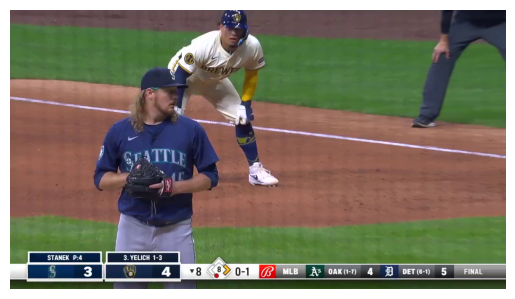

Source Image Updated to 746007_baa336bb-4b94-4bb0-95f3-9a8e0a9492e8-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746007_baa336bb-4b94-4bb0-95f3-9a8e0a9492e8-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1255.6ms
Speed: 7.4ms preprocess, 1255.6ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     639.41      246.47      145.33      198.35]]
Class Value: [          2] 

[[     542.07      222.92      140.07      299.94]]
Class Value: [          0] 

[[     622.29      434.57      141.32      361.74]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746007_baa336bb-4b94-4bb0-95f3-9a8e0a9492e8-00000.jpg


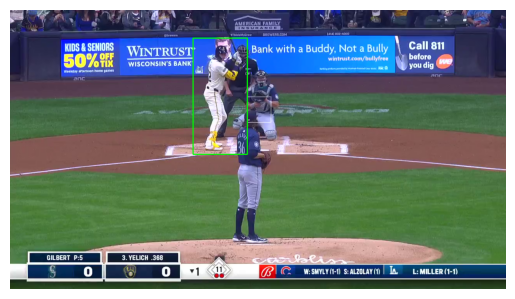

Source Image Updated to 746007_f32ac78f-52ba-4a76-b00e-450b5872067a-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746007_f32ac78f-52ba-4a76-b00e-450b5872067a-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1249.1ms
Speed: 7.9ms preprocess, 1249.1ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     642.14      249.21       123.9      177.66]]
Class Value: [          2] 

[[     542.19      221.56      138.84         301]]
Class Value: [          0] 

[[      627.9       440.6      141.67      348.34]]
Class Value: [          1] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746007_f32ac78f-52ba-4a76-b00e-450b5872067a-00000.jpg


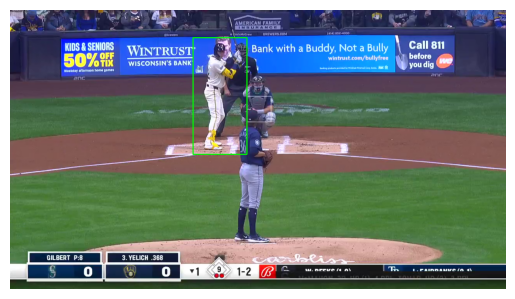

Source Image Updated to 746008_2f979359-28bd-40f2-9906-39c45aefee99-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746008_2f979359-28bd-40f2-9906-39c45aefee99-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1225.0ms
Speed: 7.5ms preprocess, 1225.0ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[      686.2      432.31       154.4      333.91]]
Class Value: [          1] 

[[     645.43      238.02      131.46       191.1]]
Class Value: [          2] 

[[     552.93      217.48      123.57      290.37]]
Class Value: [          0] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746008_2f979359-28bd-40f2-9906-39c45aefee99-00000.jpg


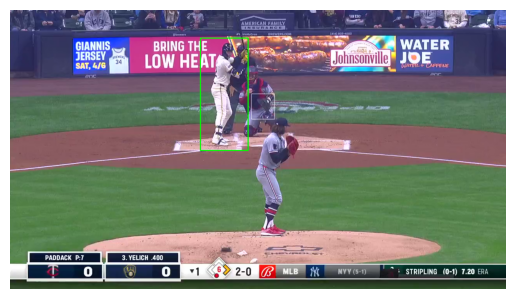

Source Image Updated to 746008_de8be275-f0e6-439f-b94f-4fdc28c89900-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746008_de8be275-f0e6-439f-b94f-4fdc28c89900-00000.png: 480x800 (no detections), 1197.6ms
Speed: 6.8ms preprocess, 1197.6ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


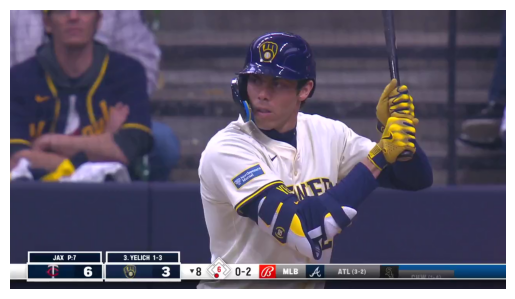

Source Image Updated to 746008_fe1decf9-aee6-4555-adc1-5bd22234401c-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746008_fe1decf9-aee6-4555-adc1-5bd22234401c-00000.png: 480x800 (no detections), 1156.3ms
Speed: 6.0ms preprocess, 1156.3ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:


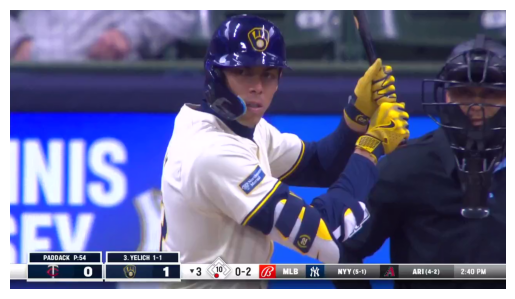

Source Image Updated to 746009_18f30a6c-85d0-4753-a93e-0723c43fa889-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746009_18f30a6c-85d0-4753-a93e-0723c43fa889-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1234.1ms
Speed: 9.1ms preprocess, 1234.1ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     588.88      424.67      134.91      313.32]]
Class Value: [          1] 

[[     546.42      223.95      113.14      271.47]]
Class Value: [          0] 

[[     642.61      253.91      113.42      159.03]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746009_18f30a6c-85d0-4753-a93e-0723c43fa889-00000.jpg


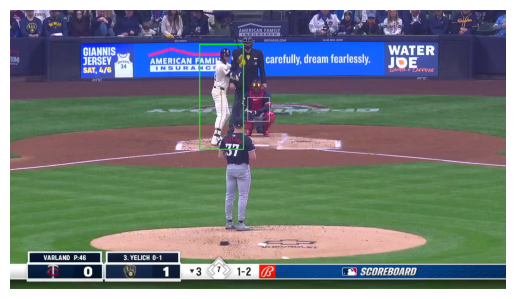

Source Image Updated to 746009_371e3c5a-59be-4e20-99a1-1448a14d417f-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746009_371e3c5a-59be-4e20-99a1-1448a14d417f-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1212.5ms
Speed: 6.0ms preprocess, 1212.5ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[      589.4      429.67      133.41      313.04]]
Class Value: [          1] 

[[     542.63      229.41      105.99      272.12]]
Class Value: [          0] 

[[     639.18      260.15      124.05      159.22]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746009_371e3c5a-59be-4e20-99a1-1448a14d417f-00000.jpg


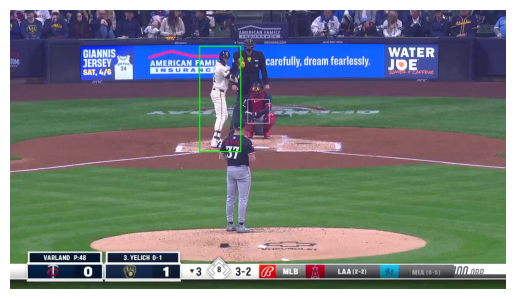

Source Image Updated to 746009_bf72c54d-770b-42dc-ad49-fd1357ad8db9-00000.png

image 1/1 C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\Yelich(592885)\hitting_frames_Yelich_2024\746009_bf72c54d-770b-42dc-ad49-fd1357ad8db9-00000.png: 480x800 1 hitter, 1 pitcher, 1 catcher, 1082.3ms
Speed: 4.4ms preprocess, 1082.3ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 800)
Results saved to C:\Users\eniko\GitHub\Automated-Posture-Analysis\Notebooks - Posture Analysis\runs\detect\predict
Return Box Predictions as Tensors:
[[     556.59      230.01      113.28      276.57]]
Class Value: [          0] 

[[     616.41      432.65      128.05      314.89]]
Class Value: [          1] 

[[     650.89      258.19      118.35      165.71]]
Class Value: [          2] 

Cropped image saved at: Yelich(592885)\cropped_images_Yelich_2024\cropped_image_746009_bf72c54d-770b-42dc-ad49-fd1357ad8db9-00000.jpg


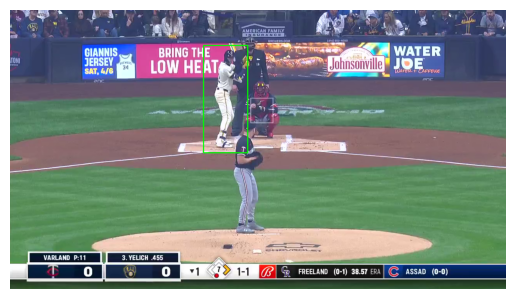

In [9]:
# go through all the images in output_frames_folder and cut out hitters 
# and save to cropped_images_output_folder

# notebook used for this part:
# https://github.com/BaseballCV/BaseballCV/blob/main/notebooks/YOLO_PHC_detection_extraction.ipynb

for file_name in os.listdir(output_frames_folder):
    if file_name.lower().endswith(".png"):
        
        #IMAGE PATH:
        SOURCE_IMAGE_PATH = output_frames_folder / file_name
        pure_name = os.path.splitext(file_name)[0]
        print("Source Image Updated to", file_name)
        
        # Box Detection with Pre-Trained Pitcher/Hitter/Catcher Detection Model
        results = model.predict(source=SOURCE_IMAGE_PATH, save=True)
        
        # Process Box Detections:
        print("Return Box Predictions as Tensors:")
        
        for r in results: #access predictions from frame
            for box in r.boxes.cpu().numpy(): #access individual boxes from frame, move to cpu memory, convert to numpy array from tensor
                print(box.xywh) #print x, y coordinate and width/height of box as tensor
                print(f"Class Value: {box.cls} \n")
        
        # Utilizing OpenCV to Visualize Predictions
        # Read the image:
        image = cv2.imread(SOURCE_IMAGE_PATH)

        # Convert image to RGB for correct matplotlib display
        image_rgb = cv2.cvtColor(image.copy(), cv2.COLOR_BGR2RGB)

        # Output folder for cropped images
        os.makedirs(cropped_images_output_folder, exist_ok=True)  # Create folder if not exists

        # Loop through all detected boxes and fint the batter: box.cls = 0
        for box in r.boxes.cpu().numpy():
            if box.cls == 0:
                x1, y1, x2, y2 = map(int, box.xyxy[0])  # Convert to integer

                # Draw rectangle/box:
                cv2.rectangle(image_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)

                # Crop and save it to folder
                cropped_img = image[y1:y2, x1:x2]
                
                save_path = os.path.join(cropped_images_output_folder, "cropped_image_"+ pure_name +".jpg")
                cv2.imwrite(save_path, cropped_img)
                
                print(f"Cropped image saved at: {save_path}")

        # Show the final image with hitter rectangle
        plt.imshow(image_rgb)
        plt.axis('off')
        plt.show()

        # Show the final image in OpenCV
        #cv2.imshow('Final Image', cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR))
        #cv2.waitKey(0)
        #cv2.destroyAllWindows()

# End of Process
Cropped images are now saved to the {player_name}({player})/cropped_images_{player_name}_{year} and next notebook can be used to get silhouette and collect Back-Gluteal line angle data:
- 02_Add Back_Gluteal line.ipynb